
# Trabajo Práctico N.º 4 – Aprendizaje por Refuerzo

**Materia:** Aprendizaje Automático II  
**Alumno:** Moisés Lobayza  
**Entorno:** LunarLander-v2

## Objetivo

Implementar y comparar tres agentes de aprendizaje por refuerzo en el entorno LunarLander-v2:

1. Política aleatoria.
2. Q-Learning tabular con discretización.
3. Deep Q-Network (DQN).

Se analizarán las recompensas, el aprendizaje y el desempeño de cada política, utilizando como base el notebook del TP3 de FrozenLake.


# Instalar dependencias

In [ ]:

%pip install -q "swig==4.3.1.post0"

%pip install -q "numpy==1.26.4" "gymnasium[box2d]==0.29.1"




  Preparing metadata (setup.py) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
dopamine-rl 4.1.2 requires gymnasium>=1.0.0, but you have gymnasium 0.29.1 which is incompatible.
jax 0.7.2 requires numpy>=2.0, but you have numpy 1.26.4 which is incompatible.
jaxlib 0.7.2 requires numpy>=2.0, but you have numpy 1.26.4 which is incompatible.
opencv-contrib-python 4.13.0.92 requires numpy>=2; python_version >= "3.9", but you have numpy 1.26.4 which is incompatible.
opencv-python 5.0.0.93 requires numpy>=2; python_version >= "3.9", but you have numpy 1.26.4 which is incompatible.
opencv-python-headless 5.0.0.93 requires numpy>=2; python_version >= "3.9", but you have numpy 1.26.4 which is incompatible.
pytensor 2.38.3 requires numpy>=2.0, but you have numpy 1.26.4 which is incompatible.
rasterio 1.5.0 requires numpy>=2, but you have numpy 1.26.4 which is in

## Importar librerías

In [ ]:
import gymnasium as gym
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import random
import imageio.v2 as imageio

import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F

from collections import deque


from IPython.display import display, Image

# Comprobar el entorno

In [ ]:
# Crear entorno
env = gym.make("LunarLander-v2")

print("Gymnasium:", gym.__version__)
print("PyTorch:", torch.__version__)
print("Observaciones:", env.observation_space)
print("Acciones:", env.action_space)
print("CUDA disponible:", torch.cuda.is_available())

# Primera observación
estado, info = env.reset(seed=42)
print("\nEstado inicial:", estado)
env.close()


Gymnasium: 0.29.1
PyTorch: 2.11.0+cpu
Observaciones: Box([-1.5       -1.5       -5.        -5.        -3.1415927 -5.
 -0.        -0.       ], [1.5       1.5       5.        5.        3.1415927 5.        1.
 1.       ], (8,), float32)
Acciones: Discrete(4)
CUDA disponible: False

Estado inicial: [ 0.00229702  1.4181306   0.2326471   0.3204666  -0.00265488 -0.05269805
  0.          0.        ]



## 1. Descripción del entorno LunarLander-v2

LunarLander-v2 es un entorno de aprendizaje por refuerzo de Gymnasium, donde un agente debe controlar un módulo espacial para aterrizar de manera segura sobre una plataforma.

### Espacio de observaciones

El entorno proporciona 8 variables:

1. Posición horizontal (x).
2. Posición vertical (y).
3. Velocidad horizontal (vx).
4. Velocidad vertical (vy).
5. Ángulo de inclinación.
6. Velocidad angular.
7. Contacto de la pata izquierda (0 o 1).
8. Contacto de la pata derecha (0 o 1).

### Espacio de acciones

El agente puede realizar cuatro acciones discretas:

- 0: No activar motores.
- 1: Activar motor lateral izquierdo.
- 2: Activar motor principal.
- 3: Activar motor lateral derecho.

### Recompensas

El agente recibe recompensas por acercarse a la plataforma, reducir su velocidad y mantener una orientación adecuada.

- Aterrizaje exitoso: +100 puntos adicionales.
- Choque: -100 puntos adicionales.
- Contacto de cada pata: +10 puntos.
- Uso de motores: penalizaciones por consumo de combustible.

El objetivo es maximizar la recompensa acumulada mediante una política que permita aterrizar de forma segura y eficiente.



## 2. Visualización del entorno

Para comprender el funcionamiento de LunarLander-v2, ejecutaremos un episodio con acciones aleatorias.

Esto permitirá observar cómo se comporta la nave sin entrenamiento y conocer la dinámica del entorno antes de implementar los algoritmos de aprendizaje por refuerzo.


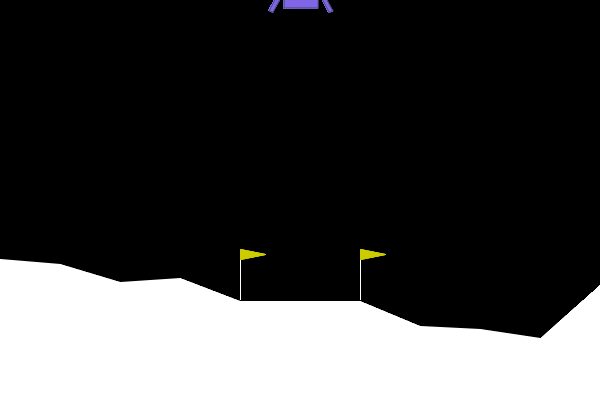

Pasos realizados: 109
Recompensa acumulada: -129.85


In [ ]:
# Crear entorno con renderizado
env_demo = gym.make("LunarLander-v2", render_mode="rgb_array")

estado, info = env_demo.reset(seed=42)

frames = [env_demo.render()]
recompensa_total = 0
pasos = 0
terminado = False

# Ejecutar episodio con acciones aleatorias
while not terminado:
    accion = env_demo.action_space.sample()

    estado, recompensa, terminated, truncated, info = env_demo.step(accion)

    recompensa_total += recompensa
    pasos += 1

    terminado = terminated or truncated

    # Guardar fotogramas para animación
    if pasos % 3 == 0 or terminado:
        frames.append(env_demo.render())

env_demo.close()

# Generar y mostrar GIF
imageio.mimsave("lunar_aleatorio.gif", frames, duration=0.12, loop=0)
display(Image(filename="lunar_aleatorio.gif"))

print(f"Pasos realizados: {pasos}")
print(f"Recompensa acumulada: {recompensa_total:.2f}")



## 3. Agente con política aleatoria

Como punto de referencia, implementaremos un agente que selecciona acciones al azar, sin utilizar la información del estado ni aprender de sus experiencias.

Evaluaremos su desempeño durante 100 episodios para obtener una recompensa promedio que posteriormente compararemos con Q-Learning y DQN.


In [ ]:

# Evaluación de la política aleatoria

env_random = gym.make("LunarLander-v2")

episodios = 1000
recompensas_random = []
duraciones_random = []

# Semilla para reproducibilidad
env_random.action_space.seed(42)

for episodio in range(episodios):

    estado, info = env_random.reset(seed=42 + episodio)

    recompensa_total = 0
    pasos = 0
    terminado = False

    while not terminado:
        accion = env_random.action_space.sample()

        estado, recompensa, terminated, truncated, info = env_random.step(accion)

        recompensa_total += recompensa
        pasos += 1
        terminado = terminated or truncated

    recompensas_random.append(recompensa_total)
    duraciones_random.append(pasos)

env_random.close()

print("RESULTADOS - POLÍTICA ALEATORIA")
print(f"Episodios: {episodios}")
print(f"Recompensa promedio: {np.mean(recompensas_random):.2f}")
print(f"Desviación estándar: {np.std(recompensas_random):.2f}")
print(f"Recompensa máxima: {np.max(recompensas_random):.2f}")
print(f"Recompensa mínima: {np.min(recompensas_random):.2f}")
print(f"Duración promedio: {np.mean(duraciones_random):.1f} pasos")


RESULTADOS - POLÍTICA ALEATORIA
Episodios: 1000
Recompensa promedio: -181.17
Desviación estándar: 108.17
Recompensa máxima: 57.28
Recompensa mínima: -514.42
Duración promedio: 92.1 pasos


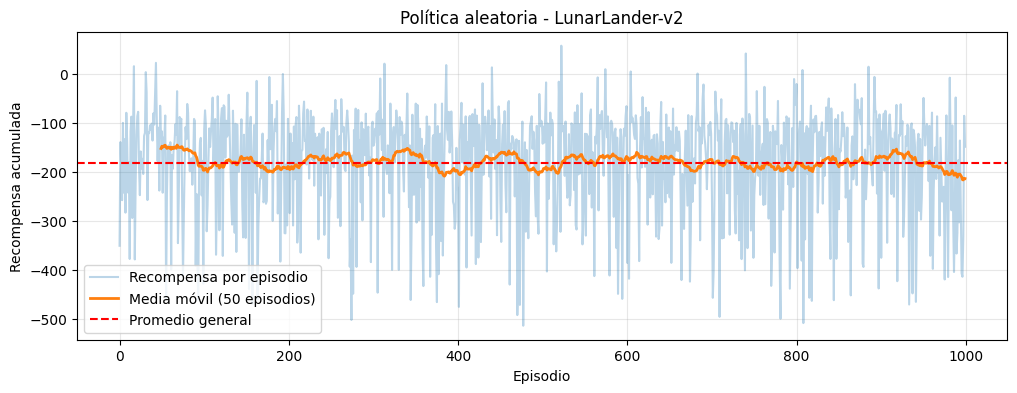

In [ ]:
media_movil = pd.Series(recompensas_random).rolling(50).mean()

plt.figure(figsize=(12, 4))
plt.plot(recompensas_random, alpha=0.3, label="Recompensa por episodio")
plt.plot(media_movil, linewidth=2, label="Media móvil (50 episodios)")
plt.axhline(np.mean(recompensas_random), color="red",
            linestyle="--", label="Promedio general")

plt.title("Política aleatoria - LunarLander-v2")
plt.xlabel("Episodio")
plt.ylabel("Recompensa acumulada")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


### Conclusión

En los 1.000 episodios evaluados, el agente aleatorio obtuvo una recompensa promedio de **−181,17**, con una desviación estándar de **108,17**.

El gráfico muestra grandes variaciones en las recompensas, pero ninguna tendencia de aprendizaje. Esto es esperable, ya que el agente selecciona acciones sin considerar el estado de la nave ni aprender de sus experiencias.

Estos resultados servirán como referencia para evaluar si Q-Learning y DQN logran mejorar el desempeño.


## 4. Q-Learning tabular

A diferencia de FrozenLake, LunarLander tiene un **espacio de observación continuo**. Para utilizar Q-Learning tabular necesitamos discretizar sus variables.

Se utilizarán inicialmente **6 intervalos para cada una de las seis variables continuas**. Las dos variables de contacto con el suelo conservarán sus valores binarios (0 o 1).

### Cálculo de estados posibles

Como tenemos 6 variables continuas divididas en 6 intervalos cada una, y 2 variables binarias:

$$
N_{\text{estados}} =
\underbrace{6^6}_{\text{6 variables continuas}}
\times
\underbrace{2^2}_{\text{2 variables binarias}}
$$

$$
N_{\text{estados}} = 46.656 \times 4 = \boxed{186.624}
$$

### Cálculo de valores Q

Cada estado tiene **4 acciones posibles** (no activar motores, motor izquierdo, motor principal y motor derecho).

Por lo tanto:

$$
N_Q = N_{\text{estados}} \times N_{\text{acciones}}
$$

$$
N_Q = 186.624 \times 4 = \boxed{746.496}
$$

En resumen:

- **186.624 estados posibles** después de discretizar.
- **4 acciones** disponibles por estado.
- **746.496 valores Q** almacenados en la tabla.

La discretización permite aplicar Q-Learning tabular, aunque introduce una pérdida de precisión que podría afectar el aprendizaje. Por este motivo, la cantidad de intervalos se considera un hiperparámetro que podremos ajustar experimentalmente.



In [ ]:

# Cantidad de intervalos por variable continua
N_BINS = 6

# Rangos elegidos para la discretización
limites = [
    (-1.5, 1.5),       # Posición x
    (0.0, 1.5),        # Posición y
    (-2.0, 2.0),       # Velocidad x
    (-2.0, 2.0),       # Velocidad y
    (-np.pi, np.pi),   # Ángulo
    (-3.0, 3.0)        # Velocidad angular
]

# Construir los puntos de corte
bins = [
    np.linspace(inferior, superior, N_BINS + 1)[1:-1]
    for inferior, superior in limites
]

def discretizar_estado(estado):
    """Convierte las 8 observaciones en índices discretos."""

    continuas = tuple(
        int(np.digitize(estado[i], bins[i]))
        for i in range(6)
    )

    contactos = tuple(
        int(valor > 0.5) for valor in estado[6:8]
    )

    return continuas + contactos


# Crear tabla Q
q_table = np.zeros(
    (N_BINS,) * 6 + (2, 2, 4),
    dtype=np.float32
)

print("Dimensiones:", q_table.shape)
print("Estados posibles:", q_table.size // 4)
print("Valores Q:", q_table.size)
print(f"Memoria: {q_table.nbytes / 1024**2:.2f} MB")

# Ejemplo de discretización
print("\nEstado original:", estado)
print("Estado discretizado:", discretizar_estado(estado))


Dimensiones: (6, 6, 6, 6, 6, 6, 2, 2, 4)
Estados posibles: 186624
Valores Q: 746496
Memoria: 2.85 MB

Estado original: [-0.4513932   0.11952518 -0.5660498  -0.10990461 -0.6060777   1.6348807
  1.          0.        ]
Estado discretizado: (2, 0, 2, 2, 2, 4, 1, 0)



### 4.1. Implementación del agente Q-Learning

Se adapta la clase `QLearningTabular` del TP3 de FrozenLake para trabajar con los estados discretizados de LunarLander.

Se mantiene el algoritmo Q-Learning con actualización mediante la ecuación de Bellman y una política de exploración ε-greedy.

Los principales cambios son:
- Discretización de las observaciones antes de consultar la tabla Q.
- Adaptación a las cuatro acciones de LunarLander.
- Reducción más gradual de epsilon, debido a la mayor cantidad de estados posibles.
- Selección aleatoria entre acciones con el mismo valor Q para evitar favorecer siempre una acción al inicio.


In [ ]:

class QLearningTabular:
    """Agente Q-Learning adaptado a LunarLander-v2."""

    def __init__(self, q_table, alpha=0.1, gamma=0.99,
                 epsilon=1.0, epsilon_decay=0.9997,
                 epsilon_min=0.05):

        self.q_table = q_table
        self.alpha = alpha
        self.gamma = gamma
        self.epsilon = epsilon
        self.epsilon_decay = epsilon_decay
        self.epsilon_min = epsilon_min
        self.rng = np.random.default_rng(42)

    def seleccionar_accion(self, estado, entrenando=True):

        estado_d = discretizar_estado(estado)

        # Exploración
        if entrenando and self.rng.random() < self.epsilon:
            return int(self.rng.integers(4))

        # Explotación
        valores_q = self.q_table[estado_d]

        # Desempate aleatorio entre mejores acciones
        mejores = np.flatnonzero(
            np.isclose(valores_q, np.max(valores_q))
        )

        return int(self.rng.choice(mejores))

    def actualizar_q(self, estado, accion, recompensa,
                     siguiente_estado, terminado):

        s = discretizar_estado(estado)
        s_next = discretizar_estado(siguiente_estado)

        q_actual = self.q_table[s + (accion,)]

        if terminado:
            objetivo = recompensa
        else:
            objetivo = recompensa + self.gamma * np.max(
                self.q_table[s_next]
            )

        self.q_table[s + (accion,)] += (
            self.alpha * (objetivo - q_actual)
        )

    def reducir_epsilon(self):
        self.epsilon = max(
            self.epsilon_min,
            self.epsilon * self.epsilon_decay
        )


In [ ]:

# Crear agente e iniciar entrenamiento

q_table.fill(0)  # Reiniciar tabla Q

agente_qlearning = QLearningTabular(q_table)

env_q = gym.make("LunarLander-v2")

episodios_q = 10000
recompensas_qlearning = []
epsilons_qlearning = []

for episodio in range(episodios_q):

    estado, info = env_q.reset(seed=42 + episodio)
    recompensa_total = 0
    finalizado = False

    while not finalizado:

        accion = agente_qlearning.seleccionar_accion(estado)

        siguiente_estado, recompensa, terminated, truncated, info = (
            env_q.step(accion)
        )

        agente_qlearning.actualizar_q(
            estado, accion, recompensa,
            siguiente_estado, terminated
        )

        recompensa_total += recompensa
        estado = siguiente_estado

        finalizado = terminated or truncated

    recompensas_qlearning.append(recompensa_total)
    epsilons_qlearning.append(agente_qlearning.epsilon)

    agente_qlearning.reducir_epsilon()

    if (episodio + 1) % 1000 == 0:

        promedio = np.mean(recompensas_qlearning[-100:])

        print(
            f"Episodio {episodio+1}/{episodios_q} | "
            f"Recompensa media (100): {promedio:.2f} | "
            f"Epsilon: {agente_qlearning.epsilon:.3f}"
        )

env_q.close()

print("\nEntrenamiento Q-Learning finalizado.")


Episodio 1000/10000 | Recompensa media (100): -121.29 | Epsilon: 0.741
Episodio 2000/10000 | Recompensa media (100): -108.48 | Epsilon: 0.549
Episodio 3000/10000 | Recompensa media (100): -98.07 | Epsilon: 0.407
Episodio 4000/10000 | Recompensa media (100): -99.45 | Epsilon: 0.301
Episodio 5000/10000 | Recompensa media (100): -122.42 | Epsilon: 0.223
Episodio 6000/10000 | Recompensa media (100): -121.31 | Epsilon: 0.165
Episodio 7000/10000 | Recompensa media (100): -99.42 | Epsilon: 0.122
Episodio 8000/10000 | Recompensa media (100): -118.18 | Epsilon: 0.091
Episodio 9000/10000 | Recompensa media (100): -68.84 | Epsilon: 0.067
Episodio 10000/10000 | Recompensa media (100): -105.65 | Epsilon: 0.050

Entrenamiento Q-Learning finalizado.



### 4.2. Evaluación inicial de Q-Learning

Luego de entrenar durante 10.000 episodios, evaluaremos la política aprendida durante 1.000 episodios adicionales, sin exploración (ε = 0).

Esto permitirá medir el rendimiento real del agente y compararlo con la política aleatoria.



In [ ]:

# Evaluación de Q-Learning sin exploración

env_eval = gym.make("LunarLander-v2")

recompensas_q_eval = []
duraciones_q_eval = []

for episodio in range(1000):

    estado, info = env_eval.reset(seed=42 + episodio)

    recompensa_total = 0
    pasos = 0
    finalizado = False

    while not finalizado:

        accion = agente_qlearning.seleccionar_accion(
            estado, entrenando=False
        )

        estado, recompensa, terminated, truncated, info = (
            env_eval.step(accion)
        )

        recompensa_total += recompensa
        pasos += 1
        finalizado = terminated or truncated

    recompensas_q_eval.append(recompensa_total)
    duraciones_q_eval.append(pasos)

env_eval.close()

print("EVALUACIÓN Q-LEARNING SIN EXPLORACIÓN")
print(f"Recompensa promedio: {np.mean(recompensas_q_eval):.2f}")
print(f"Desviación estándar: {np.std(recompensas_q_eval):.2f}")
print(f"Recompensa máxima: {np.max(recompensas_q_eval):.2f}")
print(f"Recompensa mínima: {np.min(recompensas_q_eval):.2f}")
print(f"Duración promedio: {np.mean(duraciones_q_eval):.1f} pasos")

print("\nCOMPARACIÓN CON POLÍTICA ALEATORIA")
print(f"Aleatorio: {np.mean(recompensas_random):.2f}")
print(f"Q-Learning: {np.mean(recompensas_q_eval):.2f}")


EVALUACIÓN Q-LEARNING SIN EXPLORACIÓN
Recompensa promedio: -90.80
Desviación estándar: 103.10
Recompensa máxima: 302.56
Recompensa mínima: -441.87
Duración promedio: 311.4 pasos

COMPARACIÓN CON POLÍTICA ALEATORIA
Aleatorio: -181.17
Q-Learning: -90.80


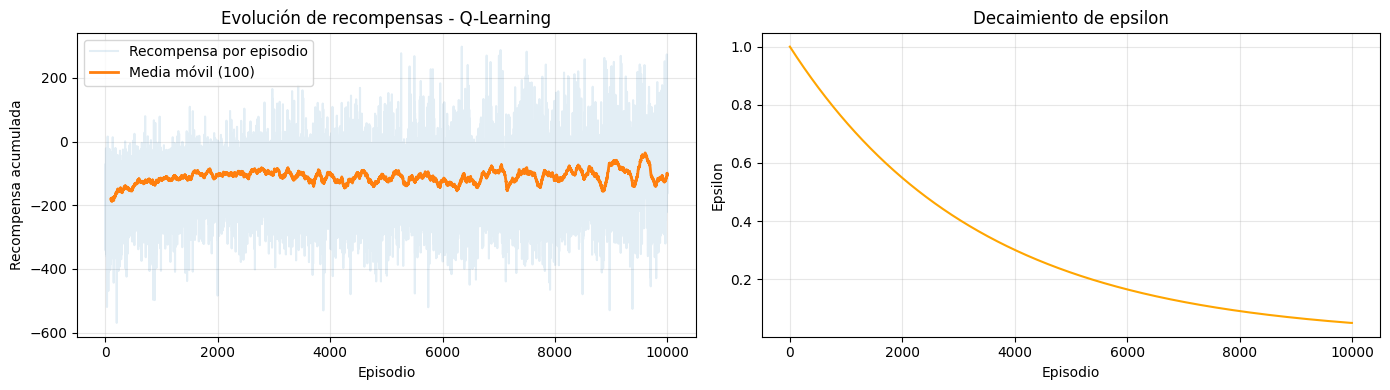

In [ ]:

# Evolución del entrenamiento Q-Learning

media_q = pd.Series(recompensas_qlearning).rolling(100).mean()

fig, ax = plt.subplots(1, 2, figsize=(14, 4))

# Recompensas
ax[0].plot(recompensas_qlearning, alpha=0.12,
           label="Recompensa por episodio")
ax[0].plot(media_q, linewidth=2,
           label="Media móvil (100)")
ax[0].set_title("Evolución de recompensas - Q-Learning")
ax[0].set_xlabel("Episodio")
ax[0].set_ylabel("Recompensa acumulada")
ax[0].legend()
ax[0].grid(alpha=0.3)

# Exploración
ax[1].plot(epsilons_qlearning, color="orange")
ax[1].set_title("Decaimiento de epsilon")
ax[1].set_xlabel("Episodio")
ax[1].set_ylabel("Epsilon")
ax[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


### Análisis de resultados de Q-Learning

Después de 10.000 episodios de entrenamiento, Q-Learning obtuvo una recompensa promedio de **−90,80** durante la evaluación sin exploración, lo que representa una mejora de **90,37 puntos** respecto de la política aleatoria.

Además, aumentó considerablemente la duración promedio de los episodios y alcanzó una recompensa máxima de **302,56**, demostrando que el agente logró aprender estrategias de aterrizaje exitosas en algunas situaciones.

Sin embargo, el rendimiento sigue siendo muy variable y la recompensa promedio continúa siendo negativa, lo que indica que el agente todavía no consigue aterrizar de manera consistente.

Una de las principales limitaciones es la **discretización de las observaciones**, ya que transforma variables continuas, como la velocidad y la inclinación de la nave, en intervalos que reducen la precisión de la información disponible.

Una posible mejora sería aumentar la cantidad de intervalos en las variables más importantes o utilizar una discretización no uniforme. No obstante, esto también incrementaría el número de estados posibles y podría requerir más episodios de entrenamiento, sin garantizar mejores resultados.

Por este motivo, resulta interesante implementar **Deep Q-Network (DQN)**, que utiliza una red neuronal para aproximar los valores Q y permite trabajar directamente con las observaciones continuas, evitando la necesidad de discretizarlas.


### 4.3. Visualización de la política aprendida

Se ejecutará un episodio utilizando la política Q-Learning entrenada, sin exploración ε-greedy.

El objetivo es observar visualmente las decisiones del agente y determinar si consigue controlar la nave, aproximarse a la plataforma y realizar un aterrizaje seguro.


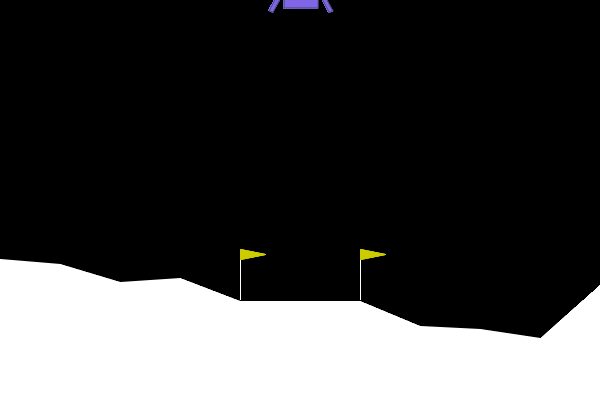

Pasos realizados: 669
Recompensa acumulada: 119.61
Terminación del entorno: True
Límite de tiempo alcanzado: False


In [ ]:

# Visualizar un episodio con Q-Learning entrenado

env_visual = gym.make("LunarLander-v2", render_mode="rgb_array")

estado, info = env_visual.reset(seed=42)

frames = [env_visual.render()]
recompensa_total = 0
pasos = 0
finalizado = False

while not finalizado:

    # Utilizar política aprendida sin exploración
    accion = agente_qlearning.seleccionar_accion(
        estado, entrenando=False
    )

    estado, recompensa, terminated, truncated, info = (
        env_visual.step(accion)
    )

    recompensa_total += recompensa
    pasos += 1
    finalizado = terminated or truncated

    if pasos % 4 == 0 or finalizado:
        frames.append(env_visual.render())

env_visual.close()

# Crear animación
imageio.mimsave(
    "lunar_qlearning.gif",
    frames,
    duration=0.12,
    loop=0
)

display(Image(filename="lunar_qlearning.gif"))

print(f"Pasos realizados: {pasos}")
print(f"Recompensa acumulada: {recompensa_total:.2f}")
print(f"Terminación del entorno: {terminated}")
print(f"Límite de tiempo alcanzado: {truncated}")


### Análisis visual de Q-Learning

En el episodio observado, el agente alcanzó una recompensa de **119,61 puntos** y permaneció activo durante **669 pasos**.

A diferencia de la política aleatoria, mostró mayor capacidad para controlar la nave y prolongar el vuelo. Sin embargo, necesitó numerosas acciones antes de finalizar y terminó fuera de la zona central de aterrizaje.

Esto sugiere que Q-Learning aprendió ciertas estrategias de control, aunque todavía presenta dificultades para conseguir aterrizajes precisos y eficientes.


## 5. Deep Q-Network (DQN)

A diferencia de Q-Learning tabular, DQN utiliza una red neuronal para aproximar la función Q(s,a).

Esto permite trabajar directamente con las ocho observaciones continuas de LunarLander, sin necesidad de **discretizarlas**.

Se utilizará una arquitectura basada en el TP3 de FrozenLake, con las siguientes características:

- Capa de entrada: 8 neuronas.
- Primera capa oculta: 128 neuronas, activación ReLU.
- Segunda capa oculta: 128 neuronas, activación ReLU.
- Capa de salida: 4 neuronas, una por cada acción posible.

También se conservarán Experience Replay y Target Network para mejorar la estabilidad del entrenamiento.

La principal adaptación respecto del TP3 consiste en reemplazar la representación one-hot de FrozenLake por las observaciones continuas originales.


In [ ]:

class DQN(nn.Module):
    """Red neuronal para aproximar la función Q."""

    def __init__(self, input_size, hidden_size, output_size):
        super(DQN, self).__init__()

        self.network = nn.Sequential(
            nn.Linear(input_size, hidden_size),
            nn.ReLU(),
            nn.Linear(hidden_size, hidden_size),
            nn.ReLU(),
            nn.Linear(hidden_size, output_size)
        )

    def forward(self, x):
        return self.network(x)


# Comprobar arquitectura
env_dqn = gym.make("LunarLander-v2")

n_estados = env_dqn.observation_space.shape[0]
n_acciones = env_dqn.action_space.n

red_dqn = DQN(n_estados, 128, n_acciones)

print(red_dqn)
print("\nEntradas:", n_estados)
print("Salidas:", n_acciones)

env_dqn.close()


DQN(
  (network): Sequential(
    (0): Linear(in_features=8, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=4, bias=True)
  )
)

Entradas: 8
Salidas: 4


# Guardar modelos y entrenamientos

In [ ]:
from google.colab import drive
from pathlib import Path

In [ ]:
drive.mount("/content/drive")

# Carpeta para guardar los entrenamientos
RUTA_MODELOS = Path(
    "/content/drive/MyDrive/TP4_LunarLander"
)

RUTA_MODELOS.mkdir(parents=True, exist_ok=True)

print("Carpeta:", RUTA_MODELOS)



Mounted at /content/drive
Carpeta: /content/drive/MyDrive/TP4_LunarLander



### 5.1. Implementación del agente DQN

Se adapta la clase DQNAgent del TP3, conservando Experience Replay, Target Network y la política ε-greedy.

Las principales modificaciones son:

- Se utilizan directamente las 8 observaciones continuas, eliminando la codificación one-hot de FrozenLake.
- El buffer de experiencias aumenta a 50.000 transiciones.
- Se utiliza un batch de 64 experiencias.
- Se aplica Smooth L1 Loss (Huber) para reducir la sensibilidad a errores elevados.
- Se actualiza la red principal cada 4 pasos del entorno.
- La red target se sincroniza cada 1.000 pasos.
- Se incorpora clipping de gradientes para mejorar la estabilidad.

Los hiperparámetros se consideran configuraciones iniciales y podrán ajustarse según los resultados.


In [ ]:

class DQNAgent:
    """Agente DQN adaptado a LunarLander-v2."""

    def __init__(self, state_size=8, action_size=4,
                 lr=0.0005, gamma=0.99,
                 epsilon=1.0, epsilon_decay=0.995,
                 epsilon_min=0.05):

        self.state_size = state_size
        self.action_size = action_size
        self.gamma = gamma

        self.epsilon = epsilon
        self.epsilon_decay = epsilon_decay
        self.epsilon_min = epsilon_min

        self.device = torch.device(
            "cuda" if torch.cuda.is_available() else "cpu"
        )

        # Red principal
        self.q_network = DQN(
            state_size, 128, action_size
        ).to(self.device)

        # Red target
        self.target_network = DQN(
            state_size, 128, action_size
        ).to(self.device)

        self.actualizar_target()

        # Optimizador
        self.optimizer = optim.Adam(
            self.q_network.parameters(), lr=lr
        )

        # Experience Replay
        self.memory = deque(maxlen=50000)
        self.batch_size = 64

        # Frecuencias de actualización
        self.train_every = 4
        self.target_update_every = 1000
        self.pasos = 0

        self.rng = random.Random(42)

        # Registro de pérdidas
        self.losses = []

        print(f"Dispositivo: {self.device}")

    def seleccionar_accion(self, estado, entrenando=True):

        # Exploración ε-greedy
        if entrenando and self.rng.random() < self.epsilon:
            return self.rng.randrange(self.action_size)

        # Observaciones continuas -> tensor
        estado_tensor = torch.as_tensor(
            estado, dtype=torch.float32,
            device=self.device
        ).unsqueeze(0)

        with torch.no_grad():
            valores_q = self.q_network(estado_tensor)

        return int(valores_q.argmax(dim=1).item())

    def recordar(self, estado, accion, recompensa,
                 siguiente_estado, terminated):

        self.memory.append((
            np.asarray(estado, dtype=np.float32).copy(),
            int(accion),
            float(recompensa),
            np.asarray(siguiente_estado, dtype=np.float32).copy(),
            bool(terminated)
        ))

        self.pasos += 1

    def aprender(self):

        if len(self.memory) < self.batch_size:
            return None

        if self.pasos % self.train_every != 0:
            return None

        batch = self.rng.sample(
            self.memory, self.batch_size
        )

        estados = torch.as_tensor(
            np.stack([e[0] for e in batch]),
            dtype=torch.float32, device=self.device
        )

        acciones = torch.as_tensor(
            [e[1] for e in batch],
            dtype=torch.long, device=self.device
        ).unsqueeze(1)

        recompensas = torch.as_tensor(
            [e[2] for e in batch],
            dtype=torch.float32, device=self.device
        )

        siguientes = torch.as_tensor(
            np.stack([e[3] for e in batch]),
            dtype=torch.float32, device=self.device
        )

        terminados = torch.as_tensor(
            [e[4] for e in batch],
            dtype=torch.float32, device=self.device
        )

        # Predicción de la red principal
        q_actual = self.q_network(estados).gather(
            1, acciones
        ).squeeze(1)

        # Objetivo calculado con la red target
        with torch.no_grad():

            q_siguiente = self.target_network(
                siguientes
            ).max(dim=1).values

            q_objetivo = (
                recompensas +
                self.gamma * q_siguiente * (1 - terminados)
            )

        # Calcular pérdida
        loss = F.smooth_l1_loss(q_actual, q_objetivo)

        # Backpropagation
        self.optimizer.zero_grad()
        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            self.q_network.parameters(), max_norm=10.0
        )

        self.optimizer.step()

        self.losses.append(loss.item())

        # Sincronizar red target
        if self.pasos % self.target_update_every == 0:
            self.actualizar_target()

        return loss.item()

    def actualizar_target(self):

        self.target_network.load_state_dict(
            self.q_network.state_dict()
        )

    def reducir_epsilon(self):

        self.epsilon = max(
            self.epsilon_min,
            self.epsilon * self.epsilon_decay
        )


In [ ]:

agente_dqn = DQNAgent(
    state_size=8,
    action_size=4
)

estado_prueba = np.zeros(8, dtype=np.float32)

accion = agente_dqn.seleccionar_accion(
    estado_prueba, entrenando=False
)

print("Acción seleccionada:", accion)
print("Experiencias almacenadas:", len(agente_dqn.memory))
print("Epsilon inicial:", agente_dqn.epsilon)


Dispositivo: cpu
Acción seleccionada: 1
Experiencias almacenadas: 0
Epsilon inicial: 1.0


In [ ]:

# Evaluación de DQN sin exploración

def evaluar_dqn(agente, n_episodios=30, semilla_base=100000):
    entorno = gym.make("LunarLander-v2")
    recompensas = []

    for episodio in range(n_episodios):
        estado, info = entorno.reset(
            seed=semilla_base + episodio
        )

        total = 0
        finalizado = False

        while not finalizado:
            accion = agente.seleccionar_accion(
                estado, entrenando=False
            )

            estado, recompensa, terminated, truncated, info = (
                entorno.step(accion)
            )

            total += recompensa
            finalizado = terminated or truncated

        recompensas.append(total)

    entorno.close()
    return float(np.mean(recompensas))


# Guardar checkpoint completo

def guardar_checkpoint_dqn(agente, episodio,
                           recompensas, historial_val,
                           mejor_validacion, mejor_episodio):

    checkpoint = {
        "episodio": episodio,
        "q_network": agente.q_network.state_dict(),
        "target_network": agente.target_network.state_dict(),
        "optimizer": agente.optimizer.state_dict(),
        "epsilon": agente.epsilon,
        "pasos": agente.pasos,
        "memory": list(agente.memory),
        "losses": agente.losses,
        "rng_agente": agente.rng.getstate(),
        "rng_torch": torch.get_rng_state(),
        "rng_numpy": np.random.get_state(),
        "recompensas": recompensas,
        "historial_validacion": historial_val,
        "mejor_validacion": mejor_validacion,
        "mejor_episodio": mejor_episodio
    }

    ruta = RUTA_MODELOS / f"dqn_checkpoint_{episodio:06d}.pt"

    torch.save(checkpoint, ruta)
    print(f"Checkpoint guardado: episodio {episodio}")


In [ ]:

# Entrenamiento DQN - LunarLander-v2

EPISODIOS_DQN = 10000

torch.manual_seed(42)
np.random.seed(42)
random.seed(42)

agente_dqn = DQNAgent(
    state_size=8,
    action_size=4,
    epsilon_decay=0.9995
)

recompensas_dqn = []
historial_validacion_dqn = []
mejor_validacion_dqn = -np.inf
mejor_episodio_dqn = 0
episodio_inicial = 0

# Buscar checkpoints anteriores
checkpoints = sorted(
    RUTA_MODELOS.glob("dqn_checkpoint_*.pt")
)

if checkpoints:
    ruta = checkpoints[-1]

    # Cargar únicamente checkpoints generados por nuestro código
    datos = torch.load(
        ruta,
        map_location=agente_dqn.device,
        weights_only=False
    )

    agente_dqn.q_network.load_state_dict(
        datos["q_network"]
    )
    agente_dqn.target_network.load_state_dict(
        datos["target_network"]
    )
    agente_dqn.optimizer.load_state_dict(
        datos["optimizer"]
    )

    agente_dqn.epsilon = datos["epsilon"]
    agente_dqn.pasos = datos["pasos"]
    agente_dqn.memory.extend(datos["memory"])
    agente_dqn.losses = datos["losses"]
    agente_dqn.rng.setstate(datos["rng_agente"])

    torch.set_rng_state(datos["rng_torch"])
    np.random.set_state(datos["rng_numpy"])

    recompensas_dqn = datos["recompensas"]
    historial_validacion_dqn = datos["historial_validacion"]
    mejor_validacion_dqn = datos["mejor_validacion"]
    mejor_episodio_dqn = datos["mejor_episodio"]
    episodio_inicial = datos["episodio"]

    print(f"Entrenamiento recuperado: episodio {episodio_inicial}")

env_train_dqn = gym.make("LunarLander-v2")

try:
    for episodio in range(episodio_inicial, EPISODIOS_DQN):

        estado, info = env_train_dqn.reset(seed=42 + episodio)

        total = 0
        finalizado = False

        while not finalizado:

            accion = agente_dqn.seleccionar_accion(estado)

            siguiente_estado, recompensa, terminated, truncated, info = (
                env_train_dqn.step(accion)
            )

            agente_dqn.recordar(
                estado, accion, recompensa,
                siguiente_estado, terminated
            )

            agente_dqn.aprender()

            total += recompensa
            estado = siguiente_estado
            finalizado = terminated or truncated

        recompensas_dqn.append(total)
        agente_dqn.reducir_epsilon()

        # Validación y guardado cada 500 episodios
        if (episodio + 1) % 500 == 0:

            media_train = np.mean(recompensas_dqn[-100:])

            media_val = evaluar_dqn(
                agente_dqn, n_episodios=30
            )

            historial_validacion_dqn.append(
                (episodio + 1, media_val)
            )

            if media_val > mejor_validacion_dqn:

                mejor_validacion_dqn = media_val
                mejor_episodio_dqn = episodio + 1

                torch.save(
                    {
                        "modelo": agente_dqn.q_network.state_dict(),
                        "episodio": mejor_episodio_dqn,
                        "validacion": mejor_validacion_dqn
                    },
                    RUTA_MODELOS / "dqn_best.pt"
                )

            print(
                f"Episodio {episodio+1}/{EPISODIOS_DQN} | "
                f"Entrenamiento: {media_train:.2f} | "
                f"Validación: {media_val:.2f} | "
                f"Epsilon: {agente_dqn.epsilon:.3f}"
            )

            guardar_checkpoint_dqn(
                agente_dqn,
                episodio + 1,
                recompensas_dqn,
                historial_validacion_dqn,
                mejor_validacion_dqn,
                mejor_episodio_dqn
            )

finally:
    env_train_dqn.close()

print("\nEntrenamiento finalizado.")
print(f"Mejor episodio: {mejor_episodio_dqn}")
print(f"Mejor validación: {mejor_validacion_dqn:.2f}")


Dispositivo: cpu
Episodio 500/10000 | Entrenamiento: -87.55 | Validación: -55.59 | Epsilon: 0.779
Checkpoint guardado: episodio 500
Episodio 1000/10000 | Entrenamiento: -55.99 | Validación: -62.08 | Epsilon: 0.606
Checkpoint guardado: episodio 1000
Episodio 1500/10000 | Entrenamiento: -12.91 | Validación: -29.46 | Epsilon: 0.472
Checkpoint guardado: episodio 1500
Episodio 2000/10000 | Entrenamiento: 19.94 | Validación: 237.08 | Epsilon: 0.368
Checkpoint guardado: episodio 2000
Episodio 2500/10000 | Entrenamiento: 29.35 | Validación: 248.25 | Epsilon: 0.286
Checkpoint guardado: episodio 2500
Episodio 3000/10000 | Entrenamiento: 92.75 | Validación: 122.28 | Epsilon: 0.223
Checkpoint guardado: episodio 3000
Episodio 3500/10000 | Entrenamiento: 144.40 | Validación: 136.50 | Epsilon: 0.174
Checkpoint guardado: episodio 3500
Episodio 4000/10000 | Entrenamiento: 212.12 | Validación: 262.53 | Epsilon: 0.135
Checkpoint guardado: episodio 4000
Episodio 4500/10000 | Entrenamiento: 186.35 | Valida


### 5.2. Evaluación de la mejor política DQN

Durante los 10.000 episodios de entrenamiento, el mejor modelo se obtuvo en el episodio 5.500, con una recompensa media de validación de 279,42.

Para evitar seleccionar necesariamente la red del último episodio, se utilizó un sistema de checkpoints que conserva el modelo con mejor rendimiento de validación.

A continuación, se evaluará el modelo seleccionado durante 1.000 episodios independientes, sin exploración, para medir su capacidad de generalización.


In [ ]:

# Recuperar mejor modelo DQN

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

checkpoint_best = torch.load(
    RUTA_MODELOS / "dqn_best.pt",
    map_location=device,
    weights_only=True
)

modelo_mejor = DQN(8, 128, 4).to(device)
modelo_mejor.load_state_dict(checkpoint_best["modelo"])
modelo_mejor.eval()

print("Mejor episodio:", checkpoint_best["episodio"])
print("Validación:", checkpoint_best["validacion"])

# Evaluación independiente
env_eval_dqn = gym.make("LunarLander-v2")

recompensas_dqn_test = []
duraciones_dqn_test = []

for episodio in range(1000):

    estado, info = env_eval_dqn.reset(
        seed=200000 + episodio
    )

    total = 0
    pasos = 0
    finalizado = False

    while not finalizado:

        estado_tensor = torch.as_tensor(
            estado, dtype=torch.float32,
            device=device
        ).unsqueeze(0)

        with torch.no_grad():
            accion = int(
                modelo_mejor(estado_tensor).argmax(dim=1).item()
            )

        estado, recompensa, terminated, truncated, info = (
            env_eval_dqn.step(accion)
        )

        total += recompensa
        pasos += 1
        finalizado = terminated or truncated

    recompensas_dqn_test.append(total)
    duraciones_dqn_test.append(pasos)

env_eval_dqn.close()

print("\nEVALUACIÓN DQN - 1000 EPISODIOS")
print(f"Recompensa promedio: {np.mean(recompensas_dqn_test):.2f}")
print(f"Desviación estándar: {np.std(recompensas_dqn_test):.2f}")
print(f"Recompensa máxima: {np.max(recompensas_dqn_test):.2f}")
print(f"Recompensa mínima: {np.min(recompensas_dqn_test):.2f}")
print(f"Duración promedio: {np.mean(duraciones_dqn_test):.1f} pasos")


Mejor episodio: 5500
Validación: 279.42275219576265

EVALUACIÓN DQN - 1000 EPISODIOS
Recompensa promedio: 272.37
Desviación estándar: 38.36
Recompensa máxima: 322.65
Recompensa mínima: 21.93
Duración promedio: 231.2 pasos


### Análisis de resultados de DQN

Luego de 10.000 episodios de entrenamiento, el modelo DQN seleccionado en el episodio 5.500 obtuvo una recompensa promedio de **272,37** durante la evaluación de 1.000 episodios independientes.

Además, presentó una desviación estándar de 38,36 y una recompensa mínima positiva de 21,93, mostrando un comportamiento considerablemente más estable que Q-Learning tabular.

Estos resultados sugieren que la red neuronal consiguió representar mejor las relaciones entre las observaciones continuas y las acciones disponibles, sin necesidad de discretizar los estados.

Sin embargo, una recompensa elevada no garantiza por sí sola un aterrizaje exitoso, por lo que también resulta importante analizar visualmente el comportamiento del agente.

# 5.3. Visualización de la política DQN

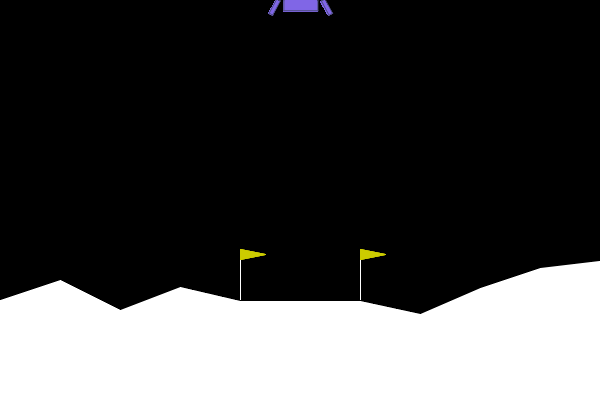

Pasos realizados: 152
Recompensa acumulada: 264.71
Terminación: True
Límite de tiempo: False


In [ ]:

# Visualizar mejor política DQN

env_visual_dqn = gym.make(
    "LunarLander-v2",
    render_mode="rgb_array"
)

estado, info = env_visual_dqn.reset(seed=200000)

frames = [env_visual_dqn.render()]
recompensa_total = 0
pasos = 0
finalizado = False

while not finalizado:

    estado_tensor = torch.as_tensor(
        estado,
        dtype=torch.float32,
        device=device
    ).unsqueeze(0)

    with torch.no_grad():
        accion = int(
            modelo_mejor(estado_tensor).argmax(dim=1).item()
        )

    estado, recompensa, terminated, truncated, info = (
        env_visual_dqn.step(accion)
    )

    recompensa_total += recompensa
    pasos += 1
    finalizado = terminated or truncated

    if pasos % 3 == 0 or finalizado:
        frames.append(env_visual_dqn.render())

env_visual_dqn.close()

imageio.mimsave(
    "lunar_dqn.gif",
    frames,
    duration=0.10,
    loop=0
)

display(Image(filename="lunar_dqn.gif"))

print(f"Pasos realizados: {pasos}")
print(f"Recompensa acumulada: {recompensa_total:.2f}")
print(f"Terminación: {terminated}")
print(f"Límite de tiempo: {truncated}")



### 5.4. Análisis del entrenamiento DQN

Para analizar el aprendizaje de DQN se presentan tres gráficos:

1. **Evolución de recompensas:** muestra las recompensas obtenidas durante los 10.000 episodios de entrenamiento y su media móvil.
2. **Rendimiento de validación:** permite observar cómo evoluciona la política sin exploración y justificar la selección del mejor checkpoint.
3. **Evolución de la pérdida (loss):** muestra cómo cambia el error de la red neuronal durante las actualizaciones de sus pesos.

Estos gráficos permitirán analizar la estabilidad del entrenamiento y determinar si el agente mejora progresivamente.


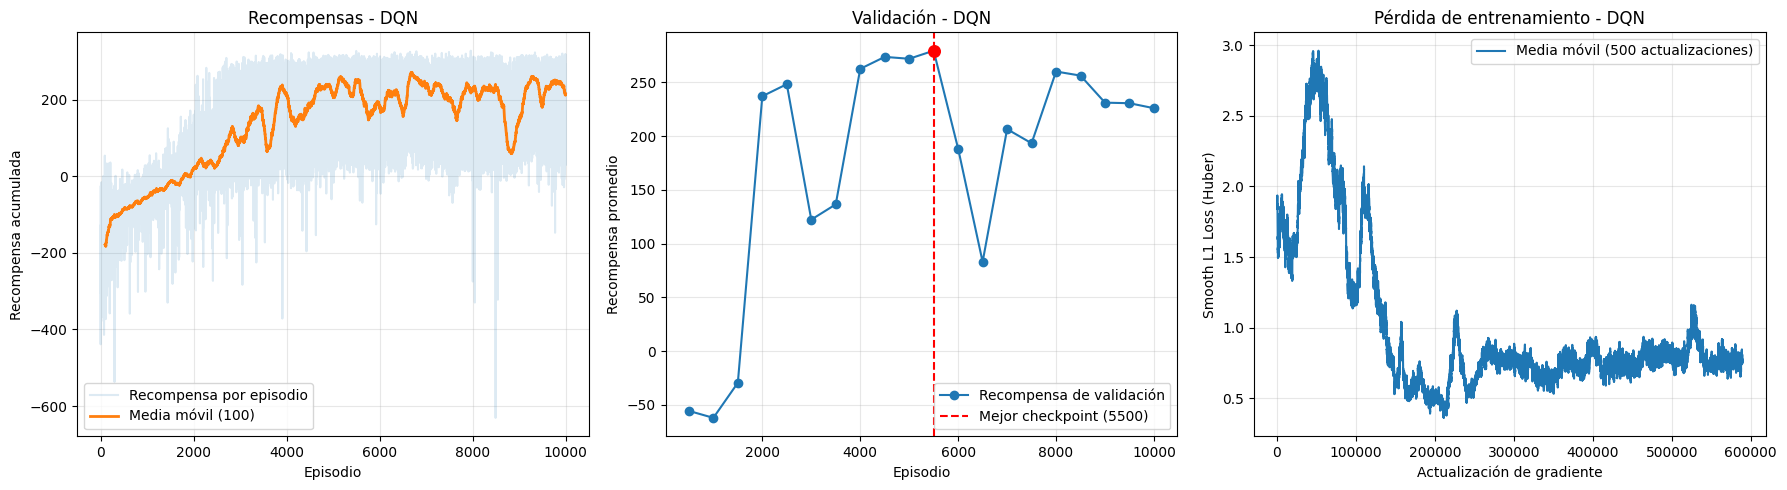

In [ ]:

# Gráficos del entrenamiento DQN

media_dqn = pd.Series(recompensas_dqn).rolling(100).mean()

validacion_dqn = np.array(historial_validacion_dqn)

losses_dqn = np.array(agente_dqn.losses)
media_loss = pd.Series(losses_dqn).rolling(500).mean()

fig, ax = plt.subplots(1, 3, figsize=(18, 5))

# 1. Evolución de recompensas
ax[0].plot(
    recompensas_dqn,
    alpha=0.15,
    label="Recompensa por episodio"
)

ax[0].plot(
    media_dqn,
    linewidth=2,
    label="Media móvil (100)"
)

ax[0].set_title("Recompensas - DQN")
ax[0].set_xlabel("Episodio")
ax[0].set_ylabel("Recompensa acumulada")
ax[0].legend()
ax[0].grid(alpha=0.3)


# 2. Evolución de validación
ax[1].plot(
    validacion_dqn[:, 0],
    validacion_dqn[:, 1],
    marker="o",
    label="Recompensa de validación"
)

ax[1].axvline(
    mejor_episodio_dqn,
    color="red",
    linestyle="--",
    label=f"Mejor checkpoint ({mejor_episodio_dqn})"
)

ax[1].scatter(
    mejor_episodio_dqn,
    mejor_validacion_dqn,
    color="red",
    s=70,
    zorder=5
)

ax[1].set_title("Validación - DQN")
ax[1].set_xlabel("Episodio")
ax[1].set_ylabel("Recompensa promedio")
ax[1].legend()
ax[1].grid(alpha=0.3)


# 3. Evolución de la pérdida
# Cada punto corresponde a una actualización de la red
ax[2].plot(
    np.arange(1, len(media_loss) + 1),
    media_loss,
    linewidth=1.5,
    label="Media móvil (500 actualizaciones)"
)

ax[2].set_title("Pérdida de entrenamiento - DQN")
ax[2].set_xlabel("Actualización de gradiente")
ax[2].set_ylabel("Smooth L1 Loss (Huber)")
ax[2].legend()
ax[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()


### Análisis del entrenamiento DQN

Durante los 10.000 episodios, DQN mostró una mejora considerable en las recompensas, pasando de valores negativos a promedios superiores a los 200 puntos.

La validación permitió identificar que el mejor modelo se obtuvo en el **episodio 5.500**, con una recompensa promedio de 279,42. Posteriormente, el rendimiento presentó fluctuaciones, demostrando que entrenar durante más episodios no garantiza necesariamente mejores resultados.

Por otro lado, la pérdida de entrenamiento disminuyó considerablemente después de las primeras actualizaciones, aunque mantuvo ciertas oscilaciones debido a la naturaleza del aprendizaje por refuerzo.

Finalmente, el modelo seleccionado obtuvo una recompensa promedio de **272,37 en 1.000 episodios de evaluación**, lo que confirma que mantuvo un rendimiento elevado en episodios independientes.

Estos resultados muestran la capacidad de DQN para aprender una política eficaz utilizando directamente las observaciones continuas de LunarLander.


## 6. Comparación de las políticas

Se comparan las tres estrategias implementadas en LunarLander-v2:

- **Política aleatoria:** selecciona acciones sin considerar el estado.
- **Q-Learning tabular:** aprende valores Q mediante una discretización de las observaciones.
- **DQN:** utiliza una red neuronal para aproximar los valores Q a partir de las observaciones continuas.

Se consideran la recompensa promedio, la desviación estándar, las recompensas máximas y mínimas, y la duración de los episodios.

Para garantizar condiciones comparables, los tres agentes se evalúan durante **1.000 episodios**, utilizando las mismas semillas (`200000–200999`).

Q-Learning y DQN se evalúan sin exploración, utilizando exclusivamente las políticas aprendidas. Las semillas de evaluación son diferentes de las utilizadas durante el entrenamiento.


### 6.1. Recuperación de la tabla Q entrenada

In [ ]:

q_table_original_10k = np.load(
    RUTA_MODELOS / "q_table_original_10k.npy"
)

print("Dimensiones:", q_table_original_10k.shape)
print("Valores Q diferentes de cero:",
      np.count_nonzero(q_table_original_10k))

# Guardar copia permanente en Google Drive
np.save(
    RUTA_MODELOS / "q_table_original_10k.npy",
    q_table_original_10k
)

print("Tabla Q recuperada y respaldada.")


Dimensiones: (6, 6, 6, 6, 6, 6, 2, 2, 4)
Valores Q diferentes de cero: 11482
Tabla Q recuperada y respaldada.


### 6.2. Evaluación final de Q-Learning

In [ ]:

# Discretización ORIGINAL: 6 intervalos uniformes

limites_originales = [
    (-1.5, 1.5),
    (0.0, 1.5),
    (-2.0, 2.0),
    (-2.0, 2.0),
    (-np.pi, np.pi),
    (-3.0, 3.0)
]

bins_originales = [
    np.linspace(a, b, 7)[1:-1]
    for a, b in limites_originales
]

def discretizar_original(estado):
    continuas = tuple(
        int(np.digitize(estado[i], bins_originales[i]))
        for i in range(6)
    )

    contactos = tuple(
        int(v > 0.5) for v in estado[6:8]
    )

    return continuas + contactos


# Evaluación con las mismas semillas de DQN
env_q_test = gym.make("LunarLander-v2")

recompensas_q_test = []
duraciones_q_test = []

for episodio in range(1000):

    semilla = 200000 + episodio
    rng = np.random.default_rng(semilla)

    estado, info = env_q_test.reset(seed=semilla)

    total = 0
    pasos = 0
    finalizado = False

    while not finalizado:

        s = discretizar_original(estado)
        valores_q = q_table_original_10k[s]

        # Política aprendida, sin exploración
        mejores = np.flatnonzero(
            np.isclose(valores_q, valores_q.max())
        )

        accion = int(rng.choice(mejores))

        estado, recompensa, terminated, truncated, info = (
            env_q_test.step(accion)
        )

        total += recompensa
        pasos += 1
        finalizado = terminated or truncated

    recompensas_q_test.append(total)
    duraciones_q_test.append(pasos)

env_q_test.close()

print("Q-LEARNING - EVALUACIÓN FINAL")
print(f"Recompensa promedio: {np.mean(recompensas_q_test):.2f}")
print(f"Desviación estándar: {np.std(recompensas_q_test):.2f}")
print(f"Recompensa máxima: {np.max(recompensas_q_test):.2f}")
print(f"Recompensa mínima: {np.min(recompensas_q_test):.2f}")
print(f"Duración promedio: {np.mean(duraciones_q_test):.1f} pasos")

# Guardar resultados
np.savez_compressed(
    RUTA_MODELOS / "evaluacion_qlearning_final.npz",
    recompensas=recompensas_q_test,
    duraciones=duraciones_q_test
)


Q-LEARNING - EVALUACIÓN FINAL
Recompensa promedio: -95.89
Desviación estándar: 101.98
Recompensa máxima: 300.09
Recompensa mínima: -466.78
Duración promedio: 321.4 pasos


### 6.3. Evaluación final de la política aleatoria

In [ ]:

# Evaluación final del agente aleatorio
# Mismas semillas que Q-Learning y DQN

env_random_test = gym.make("LunarLander-v2")

recompensas_random_test = []
duraciones_random_test = []

for episodio in range(1000):

    semilla = 200000 + episodio

    estado, info = env_random_test.reset(seed=semilla)
    env_random_test.action_space.seed(500000 + episodio)

    total = 0
    pasos = 0
    finalizado = False

    while not finalizado:

        accion = env_random_test.action_space.sample()

        estado, recompensa, terminated, truncated, info = (
            env_random_test.step(accion)
        )

        total += recompensa
        pasos += 1
        finalizado = terminated or truncated

    recompensas_random_test.append(total)
    duraciones_random_test.append(pasos)

env_random_test.close()

print("AGENTE ALEATORIO - EVALUACIÓN FINAL")
print(f"Recompensa promedio: {np.mean(recompensas_random_test):.2f}")
print(f"Desviación estándar: {np.std(recompensas_random_test):.2f}")
print(f"Recompensa máxima: {np.max(recompensas_random_test):.2f}")
print(f"Recompensa mínima: {np.min(recompensas_random_test):.2f}")
print(f"Duración promedio: {np.mean(duraciones_random_test):.1f} pasos")


AGENTE ALEATORIO - EVALUACIÓN FINAL
Recompensa promedio: -178.76
Desviación estándar: 111.42
Recompensa máxima: 83.72
Recompensa mínima: -583.13
Duración promedio: 94.2 pasos


### 6.4. Comparación de métricas y resultados

,Política,Recompensa media,Desviación estándar,Recompensa máxima,Recompensa mínima,Duración media
0,Aleatorio,-178.76,111.42,83.72,-583.13,94.21
1,Q-Learning,-95.89,101.98,300.09,-466.78,321.39
2,DQN,272.37,38.36,322.65,21.93,231.20


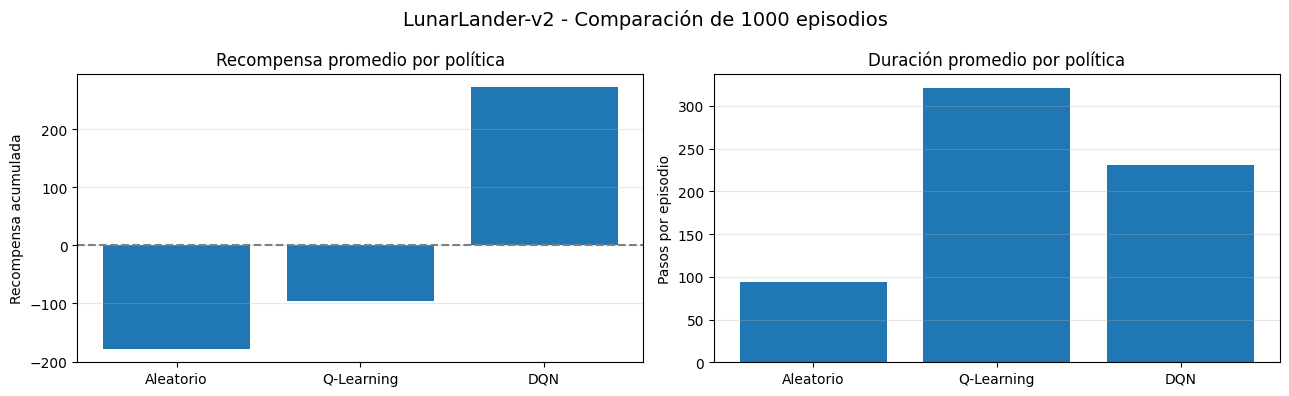

In [ ]:

# Comparación final de políticas

resultados = {
    "Aleatorio": {
        "recompensas": recompensas_random_test,
        "duraciones": duraciones_random_test
    },
    "Q-Learning": {
        "recompensas": recompensas_q_test,
        "duraciones": duraciones_q_test
    },
    "DQN": {
        "recompensas": recompensas_dqn_test,
        "duraciones": duraciones_dqn_test
    }
}

# Construir tabla de métricas
filas = []

for nombre, datos in resultados.items():
    recompensas = np.array(datos["recompensas"])
    duraciones = np.array(datos["duraciones"])

    filas.append({
        "Política": nombre,
        "Recompensa media": np.mean(recompensas),
        "Desviación estándar": np.std(recompensas),
        "Recompensa máxima": np.max(recompensas),
        "Recompensa mínima": np.min(recompensas),
        "Duración media": np.mean(duraciones)
    })

df_comparacion = pd.DataFrame(filas)

display(df_comparacion.round(2))

# Gráficos comparativos
fig, ax = plt.subplots(1, 2, figsize=(13, 4))

nombres = df_comparacion["Política"]

# Recompensas
ax[0].bar(nombres, df_comparacion["Recompensa media"])
ax[0].axhline(0, linestyle="--", color="gray")
ax[0].set_title("Recompensa promedio por política")
ax[0].set_ylabel("Recompensa acumulada")
ax[0].grid(axis="y", alpha=0.3)

# Duraciones
ax[1].bar(nombres, df_comparacion["Duración media"])
ax[1].set_title("Duración promedio por política")
ax[1].set_ylabel("Pasos por episodio")
ax[1].grid(axis="y", alpha=0.3)

plt.suptitle(
    "LunarLander-v2 - Comparación de 1000 episodios",
    fontsize=14
)

plt.tight_layout()
plt.show()


### 6.5. Guardado de resultados finales

In [ ]:

# Guardar resultados definitivos de las tres políticas

np.savez_compressed(
    RUTA_MODELOS / "evaluacion_final_politicas.npz",

    recompensas_random=np.array(recompensas_random_test),
    duraciones_random=np.array(duraciones_random_test),

    recompensas_q=np.array(recompensas_q_test),
    duraciones_q=np.array(duraciones_q_test),

    recompensas_dqn=np.array(recompensas_dqn_test),
    duraciones_dqn=np.array(duraciones_dqn_test)
)

# Guardar tabla comparativa
df_comparacion.to_csv(
    RUTA_MODELOS / "comparacion_politicas.csv",
    index=False
)

print("Resultados definitivos guardados en Google Drive.")


Resultados definitivos guardados en Google Drive.


### 6.6. Análisis comparativo de resultados

Se evaluaron las tres políticas durante 1.000 episodios independientes, utilizando las mismas semillas para garantizar condiciones comparables.

La política aleatoria obtuvo una recompensa promedio de **−178,76**, mientras que Q-Learning alcanzó **−95,89**, mejorando en 82,87 puntos. Esto demuestra que el agente tabular consiguió aprender una estrategia superior a la selección aleatoria de acciones, aunque sus resultados continuaron siendo variables.

Por su parte, **DQN obtuvo una recompensa promedio de 272,37**, superando a Q-Learning en 368,26 puntos y presentando una desviación estándar considerablemente menor (38,36 frente a 101,98).

Además, DQN consiguió resultados positivos en todos los episodios evaluados y mostró visualmente un aterrizaje preciso sobre la plataforma.

Estos resultados evidencian las ventajas de utilizar una red neuronal para aproximar la función Q en un entorno de observaciones continuas. Sin embargo, la diferencia también puede depender de los hiperparámetros y de la discretización elegida para Q-Learning, por lo que no debe interpretarse como una superioridad universal de DQN.


## 7. Visualización de las políticas aprendidas

Para visualizar las decisiones de Q-Learning y DQN, se construyen mapas de acciones en función de la posición horizontal (x) y la velocidad horizontal (vx).

Como LunarLander tiene ocho observaciones, se mantienen fijas las otras seis variables para representar una sección del espacio de estados.

Esto permite comparar cómo cada agente selecciona las acciones y observar las diferencias entre la representación tabular y la aproximación mediante una red neuronal.


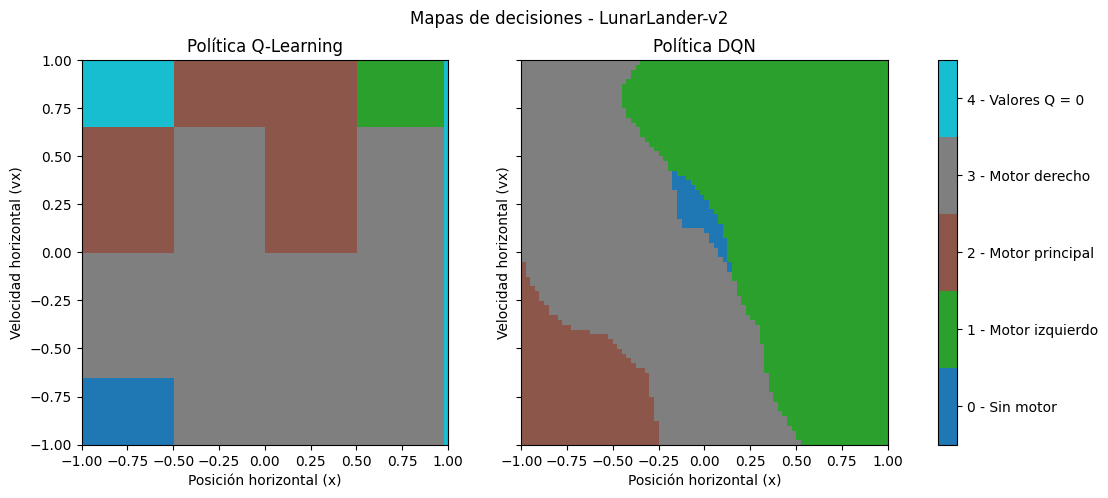

In [ ]:

# Visualización de las políticas Q-Learning y DQN

# Valores de posición y velocidad horizontal
posiciones = np.linspace(-1.0, 1.0, 80)
velocidades = np.linspace(-1.0, 1.0, 80)

X, VX = np.meshgrid(posiciones, velocidades)

# Estados de prueba: variamos x y vx
estados = np.zeros((X.size, 8), dtype=np.float32)

estados[:, 0] = X.ravel()      # Posición X
estados[:, 1] = 0.5            # Altura fija
estados[:, 2] = VX.ravel()     # Velocidad X
estados[:, 3] = -0.15          # Descenso moderado
estados[:, 4] = 0.0            # Ángulo
estados[:, 5] = 0.0            # Velocidad angular

# Política Q-Learning
acciones_q = []

for estado in estados:
    s = discretizar_original(estado)
    valores = q_table_original_10k[s]

    # 4 indica que todos los valores Q son cero
    if np.all(valores == 0):
        acciones_q.append(4)
    else:
        acciones_q.append(int(np.argmax(valores)))

acciones_q = np.array(acciones_q).reshape(X.shape)

# Política DQN
modelo_mejor.eval()

with torch.no_grad():
    tensor = torch.as_tensor(
        estados, dtype=torch.float32, device=device
    )

    acciones_dqn = (
        modelo_mejor(tensor)
        .argmax(dim=1)
        .cpu()
        .numpy()
        .reshape(X.shape)
    )

# Graficar
fig, axes = plt.subplots(1, 2, figsize=(13, 5),
                        sharex=True, sharey=True)

cmap = plt.get_cmap("tab10", 5)

for ax, acciones, titulo in zip(
    axes,
    [acciones_q, acciones_dqn],
    ["Política Q-Learning", "Política DQN"]
):
    im = ax.imshow(
        acciones,
        origin="lower",
        extent=[-1, 1, -1, 1],
        aspect="auto",
        cmap=cmap,
        vmin=-0.5,
        vmax=4.5,
        interpolation="nearest"
    )

    ax.set_title(titulo)
    ax.set_xlabel("Posición horizontal (x)")
    ax.set_ylabel("Velocidad horizontal (vx)")

cbar = fig.colorbar(im, ax=axes, ticks=range(5))
cbar.ax.set_yticklabels([
    "0 - Sin motor",
    "1 - Motor izquierdo",
    "2 - Motor principal",
    "3 - Motor derecho",
    "4 - Valores Q = 0"
])

fig.suptitle("Mapas de decisiones - LunarLander-v2")
plt.show()


### 7.1. Análisis de las políticas aprendidas

Los mapas muestran diferencias claras entre las políticas de Q-Learning y DQN.

En Q-Learning se observan regiones rectangulares, producto de la discretización de los estados. También aparecen zonas donde los valores Q permanecen en cero, lo que evidencia las limitaciones de la representación tabular.

En cambio, DQN presenta fronteras de decisión más detalladas y continuas, ya que utiliza una red neuronal para aproximar los valores Q directamente a partir de las observaciones.

Esto permite visualizar la capacidad de generalización de DQN, aunque las fronteras observadas no garantizan por sí solas mejores decisiones.

Los resultados de evaluación complementan este análisis: DQN obtuvo una recompensa promedio de **272,37**, frente a **−95,89** de Q-Learning.

In [ ]:

from PIL import Image as PILImage, ImageDraw



## 8. Comparación visual de las tres políticas

Se ejecuta un episodio con cada política utilizando la misma semilla inicial (`200000`).

Se generan tres animaciones individuales y una comparación visual simultánea, manteniendo una escala temporal común.

Esto permite observar las diferencias en el control de la nave, la duración del episodio y la precisión del aterrizaje.

Las animaciones complementan la evaluación estadística de 1.000 episodios realizada anteriormente.


Aleatorio    | Pasos:   74 | Recompensa:  -151.70
Q-Learning   | Pasos:  714 | Recompensa:  -129.18
DQN          | Pasos:  152 | Recompensa:   264.71


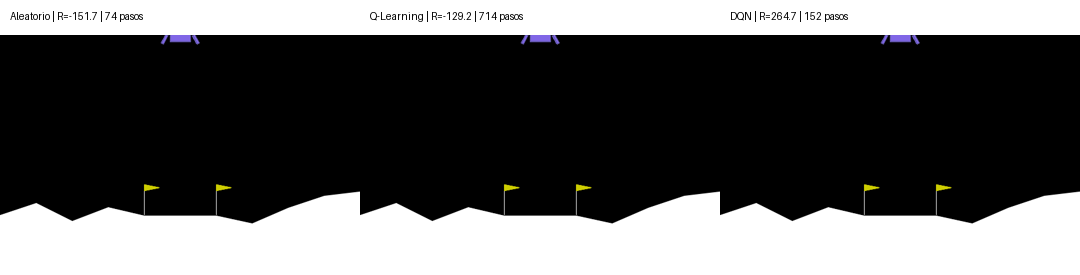

In [ ]:

# Comparación visual de las tres políticas

SEMILLA = 200000
CADA_N_PASOS = 4
ANCHO, ALTO = 360, 240


def simular_politica(nombre, semilla=SEMILLA):

    env = gym.make(
        "LunarLander-v2",
        render_mode="rgb_array"
    )

    estado, info = env.reset(seed=semilla)

    env.action_space.seed(500000)
    rng_q = np.random.default_rng(semilla)

    frames = [
        np.asarray(
            PILImage.fromarray(env.render()).resize((ANCHO, ALTO))
        )
    ]

    recompensa_total = 0
    pasos = 0

    while True:

        if nombre == "Aleatorio":
            accion = env.action_space.sample()

        elif nombre == "Q-Learning":
            s = discretizar_original(estado)
            valores_q = q_table_original_10k[s]

            mejores = np.flatnonzero(
                np.isclose(valores_q, valores_q.max())
            )

            accion = int(rng_q.choice(mejores))

        elif nombre == "DQN":
            tensor = torch.as_tensor(
                estado,
                dtype=torch.float32,
                device=device
            ).unsqueeze(0)

            with torch.no_grad():
                accion = int(
                    modelo_mejor(tensor).argmax(dim=1).item()
                )

        estado, recompensa, terminated, truncated, info = (
            env.step(accion)
        )

        recompensa_total += recompensa
        pasos += 1

        terminado = terminated or truncated

        if pasos % CADA_N_PASOS == 0 or terminado:
            imagen = PILImage.fromarray(
                env.render()
            ).resize((ANCHO, ALTO))

            frames.append(np.asarray(imagen))

        if terminado:
            break

    env.close()

    return {
        "nombre": nombre,
        "frames": frames,
        "recompensa": recompensa_total,
        "pasos": pasos
    }


# Ejecutar las tres políticas
simulaciones = [
    simular_politica("Aleatorio"),
    simular_politica("Q-Learning"),
    simular_politica("DQN")
]

# Guardar GIF individuales
for sim in simulaciones:

    ruta = RUTA_MODELOS / (
        f"animacion_{sim['nombre'].lower()}.gif"
    )

    imageio.mimsave(
        str(ruta),
        sim["frames"],
        duration=0.12,
        loop=0
    )

    print(
        f"{sim['nombre']:12} | "
        f"Pasos: {sim['pasos']:4} | "
        f"Recompensa: {sim['recompensa']:8.2f}"
    )


# Crear comparación simultánea
max_frames = max(
    len(sim["frames"]) for sim in simulaciones
)

frames_comparacion = []

for i in range(max_frames):

    lienzo = PILImage.new(
        "RGB",
        (ANCHO * 3, ALTO + 35),
        "white"
    )

    dibujo = ImageDraw.Draw(lienzo)

    for j, sim in enumerate(simulaciones):

        # Congelar el último frame si el episodio terminó
        indice = min(i, len(sim["frames"]) - 1)

        imagen = PILImage.fromarray(
            sim["frames"][indice]
        )

        lienzo.paste(imagen, (j * ANCHO, 35))

        dibujo.text(
            (j * ANCHO + 10, 10),
            f"{sim['nombre']} | R={sim['recompensa']:.1f} "
            f"| {sim['pasos']} pasos",
            fill="black"
        )

    frames_comparacion.append(np.asarray(lienzo))


ruta_comparacion = (
    RUTA_MODELOS / "comparacion_visual_politicas.gif"
)

imageio.mimsave(
    str(ruta_comparacion),
    frames_comparacion,
    duration=0.12,
    loop=0
)

display(Image(filename=str(ruta_comparacion)))


### 8.1. Análisis de la comparación visual

La comparación permite observar las diferencias entre las tres políticas utilizando las mismas condiciones iniciales.

El agente aleatorio terminó después de 74 pasos, mientras que Q-Learning permaneció activo durante 714 pasos, aunque sin conseguir un aterrizaje satisfactorio.

Por su parte, DQN logró aterrizar correctamente en 152 pasos, obteniendo una recompensa de 264,71.

Estos resultados muestran que permanecer más tiempo en el entorno no implica necesariamente un mejor desempeño. DQN aprendió una política que, en este episodio, permitió controlar la nave y completar el aterrizaje de manera más eficiente.

## 9. Conclusiones generales

En este trabajo se implementaron y compararon tres políticas de aprendizaje por refuerzo en LunarLander-v2: aleatoria, Q-Learning tabular y Deep Q-Network (DQN).

Los resultados mostraron diferencias importantes entre los métodos. La política aleatoria obtuvo una recompensa promedio de **−178,76**, mientras que Q-Learning mejoró hasta **−95,89** luego de 10.000 episodios de entrenamiento. Por su parte, DQN alcanzó una recompensa promedio de **272,37**, con una desviación estándar de 38,36 durante la evaluación de 1.000 episodios.

### Aprendizaje y resultados

Una de las principales conclusiones es la importancia de representar correctamente los estados del entorno.

En FrozenLake, utilizado en el TP3, trabajamos con estados discretos. En cambio, LunarLander tiene ocho observaciones, de las cuales seis son continuas, lo que representa un desafío importante para Q-Learning tabular.

Para resolverlo utilizamos una discretización de seis intervalos por variable continua, obteniendo 186.624 estados posibles. Si bien el agente logró mejorar respecto de la política aleatoria, la discretización limitó la precisión de las decisiones y dificultó la generalización.

Con DQN pudimos trabajar directamente con las observaciones continuas, utilizando una red neuronal para aproximar los valores Q. Esto permitió obtener una política considerablemente más eficaz, con aterrizajes visualmente más precisos y recompensas mucho más estables.

También comprobamos que **entrenar durante más episodios no garantiza necesariamente mejores resultados**. El mejor modelo DQN apareció en el episodio 5.500, por lo que guardar checkpoints y evaluar periódicamente la política resultó fundamental.

### Dificultades y experiencia

Una de las primeras dificultades fue la instalación de LunarLander-v2, debido a problemas de compatibilidad y compilación de Box2D. Esto se resolvió ajustando las versiones de las dependencias.

También tuvimos una desconexión de Google Colab durante un entrenamiento experimental de Q-Learning con discretización mejorada. Esta experiencia mostró la importancia de guardar los modelos y resultados de manera persistente en Google Drive.

Desde el punto de vista conceptual, lo más interesante fue observar cómo una red neuronal puede aprender relaciones entre estados continuos sin necesidad de construir una tabla con todas las combinaciones posibles.

Además, las animaciones y los mapas de decisiones permitieron visualizar las diferencias entre los algoritmos, complementando los resultados numéricos.

### Posibles mejoras

Una posible mejora para Q-Learning sería utilizar intervalos no uniformes y aumentar la resolución de variables críticas, como las velocidades y la inclinación. Sin embargo, esto incrementaría la cantidad de estados y podría requerir más episodios de entrenamiento.

En DQN se podrían experimentar otras arquitecturas, hiperparámetros o variantes como Double DQN. También sería interesante incorporar una medición específica de la tasa de aterrizajes exitosos, además de las recompensas acumuladas.

### Reflexión final

Este trabajo permitió profundizar lo aprendido en el TP3 y comprender mejor las ventajas y limitaciones de los distintos métodos de aprendizaje por refuerzo.

La principal conclusión es que **la representación de los estados y la capacidad de generalización son fundamentales para aprender políticas eficaces en entornos complejos**.

Aunque DQN obtuvo resultados muy superiores en este experimento, esto no significa que las redes neuronales sean siempre la mejor solución. Su implementación requiere más componentes, mayor capacidad de cálculo y un entrenamiento potencialmente inestable.

Sin embargo, para un entorno como LunarLander, los resultados muestran claramente las ventajas de aproximar la función Q mediante una red neuronal en lugar de depender exclusivamente de una tabla discretizada.

## 10. Fuentes y referencias

**1. Gymnasium – LunarLander-v2**  
Farama Foundation. Documentación oficial del entorno, espacio de observaciones, acciones y sistema de recompensas.  
https://gymnasium.farama.org/v0.29.0/environments/box2d/lunar_lander/

**2. PyTorch – Reinforcement Learning (DQN) Tutorial**  
Documentación oficial de PyTorch. Implementación de Deep Q-Network, Experience Replay y Target Network.  
https://docs.pytorch.org/tutorials/intermediate/reinforcement_q_learning

**3. DeepMind – Deep Q-Network**  
Mnih, V. et al. (2015). *Human-level control through deep reinforcement learning*. Nature, 518, 529–533.  
https://doi.org/10.1038/nature14236

**4. Gymnasium – Manejo de terminaciones y truncamientos**  
Farama Foundation. Documentación sobre la diferencia entre `terminated` y `truncated` en aprendizaje por refuerzo.  
https://gymnasium.farama.org/main/tutorials/handling_time_limits/

**5. Notebook del TP3 – Aprendizaje Automático II**  
`RL_TP3_entorno_discreto_FrozenLake.ipynb`. Material de referencia utilizado para adaptar las implementaciones de Q-Learning y DQN al entorno LunarLander-v2.

**6. OpenAI – ChatGPT (2026)**  
Herramienta de inteligencia artificial utilizada como asistencia para comprender conceptos, adaptar código, resolver errores de implementación, analizar resultados y organizar la documentación del trabajo.

El código fue ejecutado y evaluado en Google Colab, realizando las pruebas y modificaciones descritas en este notebook.

